# Churn modeling

**Goal:** predict which telecom customers will leave, explain why, and turn the model into a contact list for a retention team.

**Result.** Logistic regression with one engineered feature, `log(tenure)`, reaches **ROC-AUC 0.85** in repeated 5-fold cross-validation, on par with LightGBM and CatBoost, and stays interpretable. On the held-out test set, contacting the **20% highest-risk customers reaches 51% of all churners** (random targeting would reach 20%).

What changed compared with the first version of this notebook:

| v1 | v2 (this notebook) |
|---|---|
| `LabelEncoder` on nominal columns (imposes a fake order, e.g. DSL < Fiber < No) | `OneHotEncoder` inside a scikit-learn `Pipeline` |
| Scaler fitted in the notebook but not saved, so the API received unscaled inputs | Scaling lives in the saved pipeline; the API sends raw values |
| 11 rows with blank `TotalCharges` dropped | They are new customers (`tenure = 0`, not billed yet), filled with 0 |
| One train/test split | Repeated stratified 5-fold CV on the training set; the test set is used once |
| Feature importance from Random Forest impurity, though the chosen model was logistic regression | Permutation importance and SHAP on the final model |
| Metrics typed into MLflow by hand | Metrics computed and logged by code |

In [1]:
import logging
import sys
import warnings
from pathlib import Path

sys.path.append('..')  # import the shared pipeline from churn/
warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', message='IProgress not found')

import matplotlib as mpl
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import shap
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, classification_report,
                             precision_recall_curve, roc_auc_score)
from sklearn.model_selection import (RepeatedStratifiedKFold, StratifiedKFold,
                                     cross_val_predict, cross_validate, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler

from churn.pipeline import CATEGORICAL, FEATURES, build_pipeline, load_data

SEED = 42
FIG_DIR = Path('../data')

# Chart style: light surface, hairline grid, one accent color, muted everything else
SURFACE, INK, INK2, MUTED, GRID, AXIS = '#fcfcfb', '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'
BLUE, ORANGE, GRAY = '#2a78d6', '#eb6834', '#b4b2a9'
mpl.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': AXIS, 'axes.labelcolor': INK2, 'axes.titlecolor': INK,
    'axes.titlesize': 12, 'axes.titleweight': 'semibold', 'axes.titlelocation': 'left',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'xtick.color': AXIS, 'ytick.color': AXIS, 'xtick.labelcolor': INK2, 'ytick.labelcolor': INK2,
    'font.size': 10, 'legend.frameon': False, 'lines.linewidth': 2,
    'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
})

logging.getLogger('mlflow').setLevel(logging.WARNING)
mlflow.set_tracking_uri('sqlite:///../mlflow.db')  # same store as `python train.py --mlflow`
experiment = mlflow.set_experiment('churn-prediction')

In [2]:
X, y = load_data()
print(f'{len(X):,} customers, churn rate {y.mean():.1%}')

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y)
print(f'train {len(X_train):,} / test {len(X_test):,}. The test set is not touched until section 3.')

7,043 customers, churn rate 26.5%
train 5,634 / test 1,409. The test set is not touched until section 3.


## 1. Why `log(tenure)`?

A linear model on raw `tenure` assumes every extra month lowers churn risk by the same amount. The data says otherwise: the churn rate halves within the first year and then flattens. A log transform matches that shape, which lets a linear model capture what tree ensembles pick up on their own.

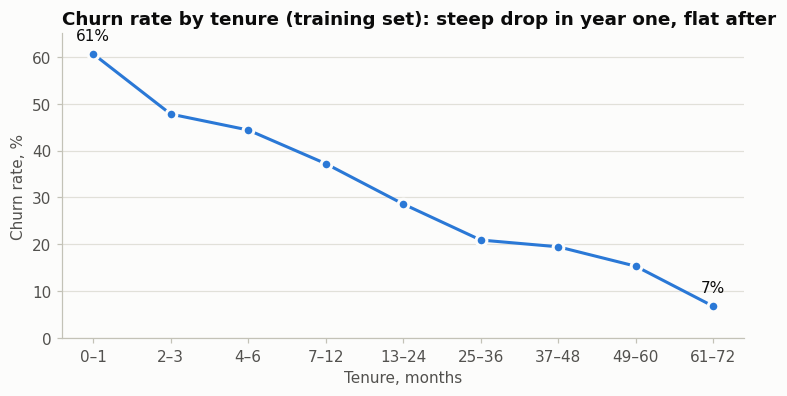

In [3]:
bins = [-1, 1, 3, 6, 12, 24, 36, 48, 60, 72]
labels = ['0–1', '2–3', '4–6', '7–12', '13–24', '25–36', '37–48', '49–60', '61–72']
rate = y_train.groupby(pd.cut(X_train['tenure'], bins=bins, labels=labels), observed=True).mean() * 100

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(labels, rate.values, color=BLUE, marker='o', markersize=7,
        markeredgecolor=SURFACE, markeredgewidth=2, solid_capstyle='round')
for i in (0, len(rate) - 1):
    ax.annotate(f'{rate.iloc[i]:.0f}%', (i, rate.iloc[i]), textcoords='offset points',
                xytext=(0, 9), ha='center', color=INK)
ax.set_ylim(0, 65)
ax.set_xlabel('Tenure, months')
ax.set_ylabel('Churn rate, %')
ax.set_title('Churn rate by tenure (training set): steep drop in year one, flat after')
ax.grid(axis='x', visible=False)
plt.show()

## 2. Model comparison

All candidates are evaluated with **repeated stratified 5-fold cross-validation** (3 repeats, 15 folds) on the training set. Preprocessing sits inside each pipeline, so every fold fits its encoders and scalers on that fold's training part only (no leakage). Every run is logged to MLflow with computed metrics.

- **LogReg, raw numerics**: one-hot + scaled `tenure`, `MonthlyCharges`, `TotalCharges`.
- **LogReg + log(tenure)**: the final model from `churn/pipeline.py`. It drops `TotalCharges`, which is ≈ `tenure × MonthlyCharges` (r = 0.83 with tenure) and adds nothing.
- **Random Forest, LightGBM, CatBoost**: all raw features; CatBoost uses its native categorical handling.

In [4]:
NUM_RAW = ['tenure', 'MonthlyCharges', 'TotalCharges']
ALL_FEATURES = CATEGORICAL + ['SeniorCitizen'] + NUM_RAW

def one_hot(numeric):
    return ColumnTransformer([
        ('cat', OneHotEncoder(drop='if_binary', handle_unknown='ignore'), CATEGORICAL),
        ('bin', 'passthrough', ['SeniorCitizen']),
        ('num', StandardScaler(), numeric),
    ])

FINAL = 'LogReg + log(tenure)'
candidates = {
    'LogReg, raw numerics': (Pipeline([('prep', one_hot(NUM_RAW)),
                                       ('model', LogisticRegression(max_iter=3000))]), ALL_FEATURES),
    FINAL: (build_pipeline(), FEATURES),
    'Random Forest': (Pipeline([('prep', one_hot(NUM_RAW)),
                                ('model', RandomForestClassifier(n_estimators=500, min_samples_leaf=10,
                                                                 random_state=SEED, n_jobs=-1))]), ALL_FEATURES),
    'LightGBM': (Pipeline([('prep', one_hot(NUM_RAW)),
                           ('model', LGBMClassifier(n_estimators=400, learning_rate=0.02, num_leaves=8,
                                                    min_child_samples=40, subsample=0.8, subsample_freq=1,
                                                    colsample_bytree=0.8, random_state=SEED, verbose=-1))]),
                 ALL_FEATURES),
    'CatBoost': (CatBoostClassifier(iterations=800, learning_rate=0.03, depth=5, l2_leaf_reg=5,
                                    random_seed=SEED, verbose=0, allow_writing_files=False), ALL_FEATURES),
}
fit_params = {'CatBoost': {'cat_features': CATEGORICAL}}  # CatBoost's native categorical handling

def loggable_params(model):
    estimator = model[-1] if isinstance(model, Pipeline) else model
    params = {k: v for k, v in estimator.get_params().items()
              if isinstance(v, (int, float, str, bool)) or v is None}
    return {'estimator': type(estimator).__name__, **params}

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=0)
rows, fold_auc = [], {}
for name, (model, columns) in candidates.items():
    scores = cross_validate(model, X_train[columns], y_train, cv=cv,
                            scoring=['roc_auc', 'average_precision'], params=fit_params.get(name))
    fold_auc[name] = scores['test_roc_auc']
    row = {'model': name,
           'cv_roc_auc': scores['test_roc_auc'].mean(),
           'cv_roc_auc_sd': scores['test_roc_auc'].std(),
           'cv_pr_auc': scores['test_average_precision'].mean()}
    rows.append(row)
    with mlflow.start_run(run_name=name):
        mlflow.log_params({**loggable_params(model), 'n_features': len(columns)})
        mlflow.log_metrics({k: v for k, v in row.items() if k != 'model'})

results = pd.DataFrame(rows).set_index('model').sort_values('cv_roc_auc', ascending=False)
results.round(4)

,cv_roc_auc,cv_roc_auc_sd,cv_pr_auc
model,,,
LogReg + log(tenure),0.8503,0.0107,0.6734
LightGBM,0.8481,0.0109,0.6681
Random Forest,0.8473,0.0102,0.6653
CatBoost,0.8458,0.0114,0.6662
"LogReg, raw numerics",0.8454,0.0101,0.6592


In [5]:
# Same folds for every model, so compare them fold by fold
for other in ['LightGBM', 'CatBoost', 'Random Forest', 'LogReg, raw numerics']:
    diff = fold_auc[FINAL] - fold_auc[other]
    print(f'{FINAL} vs {other:21s} mean ΔAUC {diff.mean():+.4f}; '
          f'LogReg ahead in {(diff > 0).sum():2d} of {len(diff)} folds')

LogReg + log(tenure) vs LightGBM              mean ΔAUC +0.0022; LogReg ahead in 13 of 15 folds
LogReg + log(tenure) vs CatBoost              mean ΔAUC +0.0045; LogReg ahead in 15 of 15 folds
LogReg + log(tenure) vs Random Forest         mean ΔAUC +0.0029; LogReg ahead in 13 of 15 folds
LogReg + log(tenure) vs LogReg, raw numerics  mean ΔAUC +0.0048; LogReg ahead in 15 of 15 folds


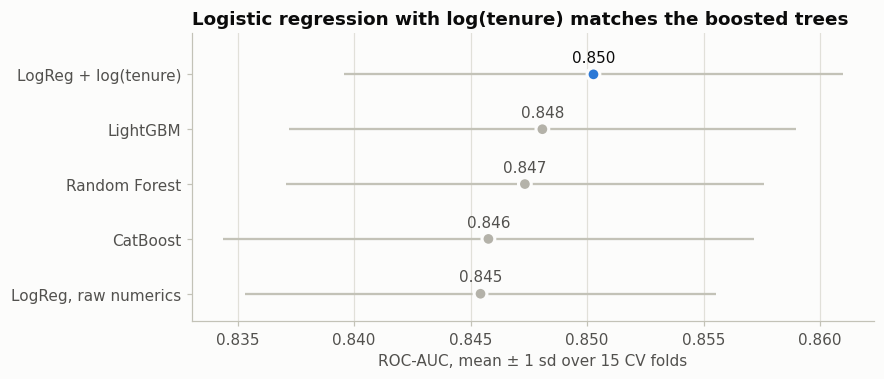

In [6]:
order = results.sort_values('cv_roc_auc').index
colors = [BLUE if m == FINAL else GRAY for m in order]

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.errorbar(results.loc[order, 'cv_roc_auc'], range(len(order)), xerr=results.loc[order, 'cv_roc_auc_sd'],
            fmt='none', ecolor=AXIS, elinewidth=1.5, capsize=0)
ax.scatter(results.loc[order, 'cv_roc_auc'], range(len(order)), s=70, c=colors,
           edgecolors=SURFACE, linewidths=2, zorder=3)
for i, m in enumerate(order):
    ax.annotate(f"{results.loc[m, 'cv_roc_auc']:.3f}", (results.loc[m, 'cv_roc_auc'], i),
                textcoords='offset points', xytext=(0, 8), ha='center', color=INK if m == FINAL else INK2)
ax.set_yticks(range(len(order)), order)
ax.set_ylim(-0.5, len(order) - 0.25)
ax.set_xlabel('ROC-AUC, mean ± 1 sd over 15 CV folds')
ax.set_title('Logistic regression with log(tenure) matches the boosted trees')
ax.grid(axis='y', visible=False)
fig.savefig(FIG_DIR / 'model_comparison.png')
plt.show()

Logistic regression with `log(tenure)` scores highest (0.850) and is ahead of LightGBM in 13 of 15 folds. The gaps between the top four models (at most 0.005) are about half the fold-to-fold spread (sd ≈ 0.01), so the fair summary is "as accurate as the boosted trees". It is kept because it is also readable, tiny and fast to serve. Without `log(tenure)`, plain logistic regression is the weakest of the five (0.845): one feature, chosen from the churn-by-tenure curve, closed the gap.

## 3. Final model on the test set

The decision threshold is chosen on **out-of-fold predictions for the training set** (maximum F1), not on the test set. `train.py` uses the same procedure.

In [7]:
oof = cross_val_predict(build_pipeline(), X_train[FEATURES], y_train, method='predict_proba',
                        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED))[:, 1]
precision, recall, thresholds = precision_recall_curve(y_train, oof)
f1 = 2 * precision[:-1] * recall[:-1] / np.clip(precision[:-1] + recall[:-1], 1e-12, None)
threshold = thresholds[f1.argmax()]

model = build_pipeline().fit(X_train[FEATURES], y_train)
proba = model.predict_proba(X_test[FEATURES])[:, 1]
test_auc, test_ap = roc_auc_score(y_test, proba), average_precision_score(y_test, proba)
print(f'Test ROC-AUC {test_auc:.3f} | PR-AUC {test_ap:.3f} (churn base rate {y_test.mean():.3f})')
print(f'Decision threshold: {threshold:.3f}\n')
print(classification_report(y_test, (proba >= threshold).astype(int), target_names=['stays', 'churns'], digits=3))

with mlflow.start_run(run_name=f'{FINAL} (test set)'):
    mlflow.log_params({**loggable_params(model), 'threshold': round(float(threshold), 4)})
    mlflow.log_metrics({'test_roc_auc': test_auc, 'test_pr_auc': test_ap})

Test ROC-AUC 0.848 | PR-AUC 0.664 (churn base rate 0.265)
Decision threshold: 0.345

              precision    recall  f1-score   support

       stays      0.887     0.800     0.841      1035
      churns      0.564     0.717     0.631       374

    accuracy                          0.778      1409
   macro avg      0.725     0.758     0.736      1409
weighted avg      0.801     0.778     0.785      1409



## 4. What drives churn

### 4.1 Why the v1 ranking was misleading

v1 ranked features by **Random Forest impurity importance** and reported `TotalCharges`, `MonthlyCharges` and `tenure` as the top three. Impurity importance is measured on training data and favors continuous features, which offer hundreds of split points; it also described a model that was not the one chosen. Below, the same v1 forest is ranked two ways. Permutation importance measures how much test ROC-AUC drops when a column is shuffled.

In [8]:
# Rebuild the v1 random forest exactly (label encoding, dropped rows). Scaling does not change trees.
raw = pd.read_csv('../data/telco_churn.csv')
raw['TotalCharges'] = pd.to_numeric(raw['TotalCharges'], errors='coerce')
v1 = raw.dropna().drop(columns='customerID')
for col in v1.select_dtypes(exclude='number').columns:
    v1[col] = LabelEncoder().fit_transform(v1[col])
Xv, yv = v1.drop(columns='Churn'), v1['Churn']
Xv_train, Xv_test, yv_train, yv_test = train_test_split(Xv, yv, test_size=0.2, random_state=SEED, stratify=yv)
rf_v1 = RandomForestClassifier(n_estimators=100, random_state=SEED).fit(Xv_train, yv_train)

perm_v1 = permutation_importance(rf_v1, Xv_test, yv_test, scoring='roc_auc', n_repeats=30, random_state=SEED)
v1_ranks = pd.DataFrame({
    'rank by impurity (v1)': pd.Series(rf_v1.feature_importances_, index=Xv.columns).rank(ascending=False),
    'rank by permutation (test set)': pd.Series(perm_v1.importances_mean, index=Xv.columns).rank(ascending=False),
}).astype(int).sort_values('rank by impurity (v1)')
v1_ranks.head(8)

,rank by impurity (v1),rank by permutation (test set)
TotalCharges,1,6
MonthlyCharges,2,11
tenure,3,2
Contract,4,1
PaymentMethod,5,13
OnlineSecurity,6,4
TechSupport,7,5
gender,8,19


Measured on held-out data, `TotalCharges` and `MonthlyCharges` fall out of the forest's own top three. Contract type and tenure carry the predictions.

### 4.2 Final model: permutation importance and SHAP

Both methods are computed for the logistic regression that is actually served. Permutation importance shuffles raw columns, so a one-hot-encoded feature is shuffled as a whole. SHAP values (`LinearExplainer`, log-odds scale) of the one-hot columns are summed back to the original feature.

In [9]:
perm = permutation_importance(model, X_test[FEATURES], y_test, scoring='roc_auc', n_repeats=30, random_state=SEED)

prep, logreg = model.named_steps['prep'], model.named_steps['model']
names = prep.get_feature_names_out()
shap_values = shap.LinearExplainer(logreg, prep.transform(X_train[FEATURES])).shap_values(
    prep.transform(X_test[FEATURES]))

def source_feature(name):
    block, column = name.split('__', 1)
    if block != 'cat':
        return column
    return next(f for f in sorted(CATEGORICAL, key=len, reverse=True) if column.startswith(f + '_'))

shap_by_feature = pd.DataFrame(shap_values, columns=names).T.groupby([source_feature(n) for n in names]).sum().T
importance = pd.DataFrame({
    'permutation: ROC-AUC drop': pd.Series(perm.importances_mean, index=FEATURES),
    'mean |SHAP|, log-odds': shap_by_feature.abs().mean(),
}).sort_values('mean |SHAP|, log-odds', ascending=False)
importance.round(3).head(10)

,permutation: ROC-AUC drop,"mean |SHAP|, log-odds"
tenure,0.094,0.673
InternetService,0.039,0.606
Contract,0.046,0.596
MonthlyCharges,0.022,0.419
StreamingMovies,0.004,0.244
MultipleLines,0.004,0.241
StreamingTV,0.004,0.229
PaperlessBilling,0.002,0.188
OnlineSecurity,0.002,0.175
TechSupport,0.002,0.151


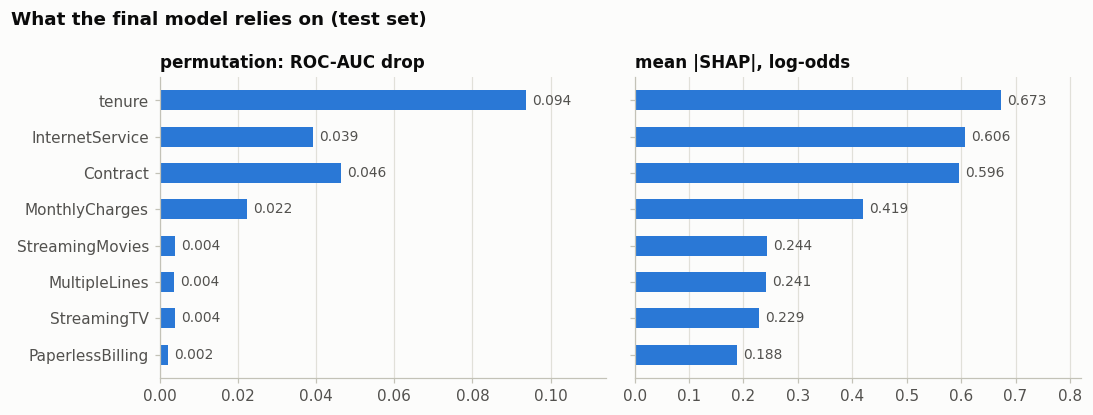

In [10]:
top = importance.head(8).iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, column in zip(axes, importance.columns):
    ax.barh(top.index, top[column], height=0.55, color=BLUE)
    for i, v in enumerate(top[column]):
        ax.annotate(f'{v:.3f}', (v, i), textcoords='offset points', xytext=(4, 0), va='center', color=INK2, fontsize=9)
    ax.set_title(column, fontsize=11)
    ax.grid(axis='y', visible=False)
    ax.set_xlim(0, top[column].max() * 1.22)
fig.suptitle('What the final model relies on (test set)', x=0.01, ha='left', fontsize=12, fontweight='semibold', color=INK)
fig.tight_layout()
fig.savefig(FIG_DIR / 'feature_importance.png')
plt.show()

### 4.3 Effect sizes

Odds ratios from the logistic regression, holding everything else fixed. Two caveats:

- The monthly bill is almost fully determined by the services a customer has, and both are in the model. That is why `MonthlyCharges` gets a negative coefficient, and why the fiber-vs-DSL ratio compares customers *with the same bill*. Read services and bill together.
- These are associations in historical data, not the effect of moving a customer to another contract. Measuring that would take an experiment, for example a randomized contract-upgrade offer.

In [11]:
coef = pd.Series(logreg.coef_[0], index=names)
log_tenure_sd = prep.named_transformers_['log'][-1].scale_[0]

def odds_ratio(a, b):
    return np.exp(coef[a] - coef[b])

def tenure_odds_ratio(months_from, months_to):
    return np.exp(coef['log__tenure'] / log_tenure_sd * (np.log1p(months_to) - np.log1p(months_from)))

effects = pd.Series({
    'Two-year vs month-to-month contract': odds_ratio('cat__Contract_Two year', 'cat__Contract_Month-to-month'),
    'One-year vs month-to-month contract': odds_ratio('cat__Contract_One year', 'cat__Contract_Month-to-month'),
    'Tenure 24 vs 3 months': tenure_odds_ratio(3, 24),
    'Fiber optic vs DSL internet': odds_ratio('cat__InternetService_Fiber optic', 'cat__InternetService_DSL'),
    'Electronic check vs automatic card payment': odds_ratio('cat__PaymentMethod_Electronic check',
                                                              'cat__PaymentMethod_Credit card (automatic)'),
    'Paperless billing vs paper bill': np.exp(coef['cat__PaperlessBilling_Yes']),
}, name='odds ratio for churn')
effects.round(2).to_frame()

,odds ratio for churn
Two-year vs month-to-month contract,0.19
One-year vs month-to-month contract,0.49
Tenure 24 vs 3 months,0.28
Fiber optic vs DSL internet,3.85
Electronic check vs automatic card payment,1.43
Paperless billing vs paper bill,1.47


## 5. Business view: whom to contact

A retention team cannot call everyone. The table shows what share of all churners is reached when the team contacts the top X% of customers ranked by predicted risk (test set).

In [12]:
ranked = y_test.to_numpy()[np.argsort(-proba)]
reached = np.cumsum(ranked) / ranked.sum()
n = len(ranked)

gains = pd.DataFrame({'contacted': [0.1, 0.2, 0.3, 0.4, 0.5]})
k = (gains['contacted'] * n).round().astype(int)
gains['churners reached'] = reached[k - 1]
gains['precision'] = [ranked[:i].mean() for i in k]
gains['lift vs random'] = gains['churners reached'] / gains['contacted']
gains.style.format({'contacted': '{:.0%}', 'churners reached': '{:.1%}', 'precision': '{:.1%}',
                    'lift vs random': '{:.2f}x'}).hide(axis='index')

contacted,churners reached,precision,lift vs random
10%,28.9%,76.6%,2.89x
20%,51.1%,67.7%,2.55x
30%,66.0%,58.4%,2.20x
40%,77.5%,51.4%,1.94x
50%,87.4%,46.4%,1.75x


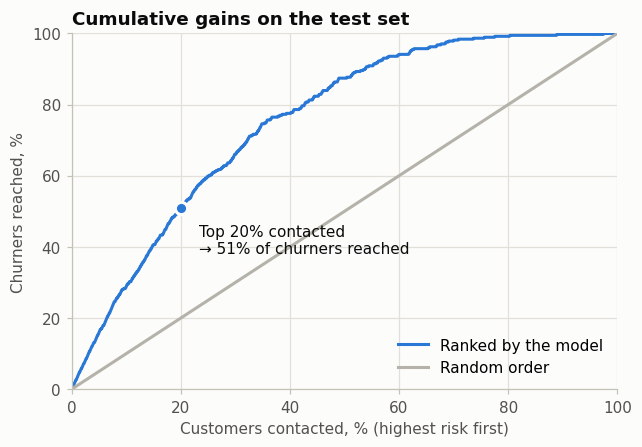

In [13]:
share = np.arange(1, n + 1) / n
top20 = int(round(0.2 * n)) - 1

fig, ax = plt.subplots(figsize=(6.4, 4.2))
ax.plot(np.r_[0, share] * 100, np.r_[0, reached] * 100, color=BLUE, label='Ranked by the model')
ax.plot([0, 100], [0, 100], color=GRAY, label='Random order')
ax.scatter([share[top20] * 100], [reached[top20] * 100], s=64, color=BLUE, edgecolors=SURFACE, linewidths=2, zorder=3)
ax.annotate(f'Top 20% contacted\n→ {reached[top20]:.0%} of churners reached', (share[top20] * 100, reached[top20] * 100),
            textcoords='offset points', xytext=(12, -30), color=INK)
ax.set_xlim(0, 100); ax.set_ylim(0, 100)
ax.set_xlabel('Customers contacted, % (highest risk first)')
ax.set_ylabel('Churners reached, %')
ax.set_title('Cumulative gains on the test set')
ax.legend(loc='lower right')
fig.savefig(FIG_DIR / 'gains_curve.png')
plt.show()

## 6. Serving

`train.py` fits this exact pipeline on all 7,043 customers, picks the threshold as above, and saves the model for `app/main.py`. The API accepts raw values (`"Contract": "Month-to-month"`), validates them with pydantic, and `tests/test_api.py` checks that its answers match the pipeline's predictions on real rows, so the v1 train/serve mismatch cannot come back unnoticed.